# Regresie logistică și metrici de clasificare — rezolvări

Datele se citesc din `Human_Activity_Recognition_Using_Smartphones_Data.csv`, aflat în directorul acestui notebook. Rulați celulele în ordine.

# Obiectivele învățării

- Descrieți regresia logistică și modul în care aceasta diferă de regresia liniară
- Identificarea metricilor pentru erorile de clasificare și scenariile în care acestea pot fi utilizate


## Introducere

Vom utiliza baza de date [Human Activity Recognition with Smartphones] (https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), care a fost construită pe baza înregistrărilor participanților la studiu care efectuează activități de viață zilnică (ADL) în timp ce poartă un smartphone cu senzori inerțiali încorporați. Obiectivul este de a clasifica activitățile într-una dintre cele șase activități (mersul pe jos, mersul pe scări, mersul pe scări, șezutul, statul în picioare și întinderea) efectuate.

Pentru fiecare înregistrare din setul de date se furnizează: 

- accelerația triaxială de la accelerometru (accelerația totală) și accelerația corpului estimată. 
- Viteza triaxială unghiulară de la giroscop. 
- Un vector de 561 de caracteristici cu variabile în domeniul timpului și al frecvenței. 
- Eticheta activității sale. 

Mai multe informații despre caracteristici sunt disponibile pe site-ul de mai sus.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
DATA_FILE = Path('Human_Activity_Recognition_Using_Smartphones_Data.csv')
if not DATA_FILE.is_file():
    raise FileNotFoundError(f'Nu găsesc {DATA_FILE.resolve()}. Rulați notebookul din directorul laboratorului.')

## Întrebarea 1

Importați datele și faceți următoarele:

* Examinați tipurile de date - există multe coloane, astfel încât ar putea fi înțelept să folosiți numărătoarea valorilor
* Determinați dacă valorile în virgulă flotantă trebuie să fie scalate
* Determinați defalcarea fiecărei activități
* Codificați eticheta activității ca un număr întreg

In [2]:
df = pd.read_csv(DATA_FILE)
print(f'Dimensiune: {df.shape[0]} observații × {df.shape[1]} coloane')
display(df.dtypes.value_counts().rename_axis('Tip de date').to_frame('Număr de coloane'))
print('Valori lipsă:', int(df.isna().sum().sum()))

X = df.drop(columns='Activity')
if not all(pd.api.types.is_numeric_dtype(t) for t in X.dtypes):
    raise TypeError('Există caracteristici nenumerice în CSV.')
print(f'Intervalul caracteristicilor: [{X.min().min():.4f}, {X.max().max():.4f}]')
print('Toate valorile din [-1, 1]:', bool(X.ge(-1).all().all() and X.le(1).all().all()))
display(df['Activity'].value_counts().rename_axis('Activitate').to_frame('Observații'))

encoder = LabelEncoder()
y = encoder.fit_transform(df['Activity'])
display(pd.DataFrame({'Cod': range(len(encoder.classes_)), 'Activitate': encoder.classes_}))
sample_idx = df.sample(n=5, random_state=RANDOM_STATE).index
display(pd.DataFrame({'Activitate': df.loc[sample_idx, 'Activity'], 'Cod': y[sample_idx]}))

Dimensiune: 10299 observații × 562 coloane


,Număr de coloane
Tip de date,
float64,561
str,1


Valori lipsă: 0
Intervalul caracteristicilor: [-1.0000, 1.0000]
Toate valorile din [-1, 1]: True


,Observații
Activitate,
LAYING,1944
STANDING,1906
SITTING,1777
WALKING,1722
WALKING_UPSTAIRS,1544
WALKING_DOWNSTAIRS,1406


,Cod,Activitate
0,0,LAYING
1,1,SITTING
2,2,STANDING
3,3,WALKING
4,4,WALKING_DOWNSTAIRS
5,5,WALKING_UPSTAIRS


,Activitate,Cod
5804,WALKING,3
3688,LAYING,0
7360,STANDING,2
3437,STANDING,2
8193,WALKING,3


**Răspuns:** Setul conține 10.299 observații, 561 caracteristici `float64` și ținta categorială `Activity`, fără valori lipsă. Toate caracteristicile sunt deja în [-1, 1], deci nu necesită o nouă scalare. Cele șase clase au între 1.406 și 1.944 observații; `LabelEncoder` le codifică de la 0 la 5.

## Întrebarea 2

* Calculați corelațiile dintre variabilele dependente.
* Creați o histogramă a valorilor corelației
* Identificați cele care sunt cele mai corelate (fie pozitiv, fie negativ).

Calculăm corelațiile dintre caracteristicile explicative. Folosim fiecare pereche o singură dată, fără diagonală; corelațiile nedefinite sunt excluse.

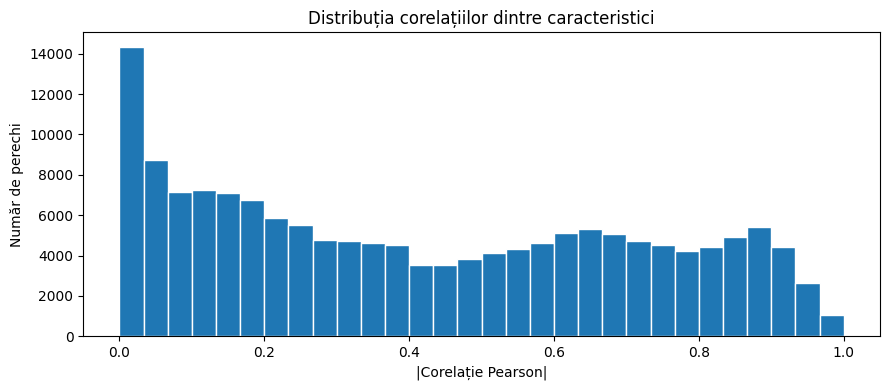

Cele mai puternice corelații pozitive:


,Caracteristica 1,Caracteristica 2,Corelație
112405,tBodyAccMag-mean(),tBodyAccMag-sma(),1.0
112413,tBodyAccMag-mean(),tGravityAccMag-mean(),1.0
112418,tBodyAccMag-mean(),tGravityAccMag-sma(),1.0
112975,tBodyAccMag-std(),tGravityAccMag-std(),1.0
113537,tBodyAccMag-mad(),tGravityAccMag-mad(),1.0
114099,tBodyAccMag-max(),tGravityAccMag-max(),1.0
114661,tBodyAccMag-min(),tGravityAccMag-min(),1.0
115218,tBodyAccMag-sma(),tGravityAccMag-mean(),1.0
115223,tBodyAccMag-sma(),tGravityAccMag-sma(),1.0
115785,tBodyAccMag-energy(),tGravityAccMag-energy(),1.0


Cele mai puternice corelații negative:


,Caracteristica 1,Caracteristica 2,Corelație
41027,"tGravityAcc-arCoeff()-Z,1","tGravityAcc-arCoeff()-Z,2",-0.995195
24122,tGravityAcc-mean()-Z,"angle(Z,gravityMean)",-0.994764
41589,"tGravityAcc-arCoeff()-Z,2","tGravityAcc-arCoeff()-Z,3",-0.994628
42151,"tGravityAcc-arCoeff()-Z,3","tGravityAcc-arCoeff()-Z,4",-0.994267
23560,tGravityAcc-mean()-Y,"angle(Y,gravityMean)",-0.993425
29171,tGravityAcc-max()-Z,"angle(Z,gravityMean)",-0.992689
38779,"tGravityAcc-arCoeff()-Y,1","tGravityAcc-arCoeff()-Y,2",-0.991609
28609,tGravityAcc-max()-Y,"angle(Y,gravityMean)",-0.991255
30854,tGravityAcc-min()-Z,"angle(Z,gravityMean)",-0.990748
30292,tGravityAcc-min()-Y,"angle(Y,gravityMean)",-0.990459


Perechi cu |r| ≥ 0,9: 8093


In [3]:
corr = X.corr(numeric_only=True)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().rename('Corelație').reset_index()
pairs.columns = ['Caracteristica 1', 'Caracteristica 2', 'Corelație']
pairs['Valoare absolută'] = pairs['Corelație'].abs()

plt.figure(figsize=(9, 4))
plt.hist(pairs['Valoare absolută'], bins=30, edgecolor='white')
plt.xlabel('|Corelație Pearson|')
plt.ylabel('Număr de perechi')
plt.title('Distribuția corelațiilor dintre caracteristici')
plt.tight_layout()
plt.show()
print('Cele mai puternice corelații pozitive:')
display(pairs.nlargest(10, 'Corelație').drop(columns='Valoare absolută'))
print('Cele mai puternice corelații negative:')
display(pairs.nsmallest(10, 'Corelație').drop(columns='Valoare absolută'))
print('Perechi cu |r| ≥ 0,9:', int(pairs['Valoare absolută'].ge(0.9).sum()))

**Răspuns:** Există 8.093 perechi cu |r| ≥ 0,9. Mai multe caracteristici de magnitudine au corelație pozitivă perfectă (r = 1), iar cea mai puternică corelație negativă este între `tGravityAcc-arCoeff()-Z,1` și `tGravityAcc-arCoeff()-Z,2` (r ≈ -0,995). Redundanța motivează regularizarea.

## Întrebare 3

* Împărțiți datele în seturi de date de instruire și de testare. Acest lucru se poate face folosind orice metodă, dar luați în considerare utilizarea `StratifiedShuffleSplit` din Scikit-learn pentru a menține același raport al claselor de predictori.
* Indiferent de metodele utilizate pentru împărțirea datelor, comparați raportul claselor în ambele împărțiri, de formare și de testare.


In [4]:
splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
class_balance = pd.DataFrame({
    'Activitate': encoder.classes_,
    'Antrenare': np.bincount(y_train, minlength=len(encoder.classes_)) / len(y_train),
    'Test': np.bincount(y_test, minlength=len(encoder.classes_)) / len(y_test),
})
class_balance['Diferență absolută'] = (class_balance['Antrenare'] - class_balance['Test']).abs()
print(f'Antrenare: {len(y_train)}; test: {len(y_test)}')
display(class_balance)

Antrenare: 8239; test: 2060


,Activitate,Antrenare,Test,Diferență absolută
0,LAYING,0.188736,0.188835,0.000098
1,SITTING,0.172472,0.172816,0.000343
2,STANDING,0.185095,0.184951,0.000144
3,WALKING,0.167253,0.166990,0.000263
4,WALKING_DOWNSTAIRS,0.136546,0.136408,0.000138
5,WALKING_UPSTAIRS,0.149897,0.150000,0.000103


**Răspuns:** Împărțirea produce 8.239 observații pentru antrenare și 2.060 pentru test. Cea mai mare diferență între proporțiile unei clase este sub 0,04 puncte procentuale. Setul de test rămâne separat de alegerea hiperparametrilor.

## Întrebare 4

* Ajustați un model de regresie logistică fără regularizare folosind toate caracteristicile. Asigurați-vă că citiți documentația despre ajustarea unui model multiclasă, astfel încât să înțelegeți coeficientul de ieșire. Stocați modelul.
* Folosind validarea încrucișată pentru a determina hiperparametrii, ajustați modelele folosind regularizarea L1 și L2. De asemenea, stocați fiecare dintre aceste modele. Rețineți limitările privind modelele, soluțiile și regularizările multiclasă. Modelele regularizate, în special modelul L1, vor dura probabil ceva timp pentru a fi ajustate.

Folosim regresie logistică multinomială. `coef_` are șase rânduri, câte unul pentru fiecare activitate, și 561 coloane. Pentru L1 și L2 alegem `C` prin validare încrucișată pe datele de antrenare. `C` mai mic înseamnă regularizare mai puternică. `saga` acceptă regularizarea L1 multinomială.

In [5]:
model_none = LogisticRegression(C=np.inf, solver='saga', max_iter=2000,
                                tol=0.005, random_state=RANDOM_STATE)
model_l1 = LogisticRegressionCV(
    Cs=[0.01, 0.1, 1.0, 10.0], l1_ratios=[1.0], cv=3, solver='saga',
    scoring='accuracy', max_iter=1500, tol=0.01, random_state=RANDOM_STATE,
    n_jobs=-1, use_legacy_attributes=False)
model_l2 = LogisticRegressionCV(
    Cs=[0.01, 0.1, 1.0, 10.0], l1_ratios=[0.0], cv=3, solver='saga',
    scoring='accuracy', max_iter=1500, tol=0.005, random_state=RANDOM_STATE,
    n_jobs=-1, use_legacy_attributes=False)

models = {'Fără regularizare': model_none, 'L1': model_l1, 'L2': model_l2}
for name, model in models.items():
    print(f'Antrenez: {name}')
    model.fit(X_train, y_train)
    if hasattr(model, 'C_'):
        print('  C ales prin CV:', model.C_)
    print('  Dimensiunea coeficienților:', model.coef_.shape)

Antrenez: Fără regularizare
  Dimensiunea coeficienților: (6, 561)
Antrenez: L1
  C ales prin CV: 10.0
  Dimensiunea coeficienților: (6, 561)
Antrenez: L2
  C ales prin CV: 10.0
  Dimensiunea coeficienților: (6, 561)


**Răspuns:** Toate modelele au șase vectori de câte 561 coeficienți. Validarea încrucișată a ales `C=10` pentru L1 și L2 din grila evaluată. Dacă apare un avertisment de neconvergență la o nouă rulare, măriți `max_iter`.

## Întrebarea 5

Comparați mărimile coeficienților pentru fiecare dintre modele. Dacă s-a utilizat ajustarea unu-vs-rest, fiecare set de coeficienți poate fi reprezentat separat. 

Pregătiți șase diagrame separate pentru fiecare dintre coeficienții multi-clasă.

,Media |coeficient|,Maxim |coeficient|,Coeficienți zero
Model,,,
Fără regularizare,0.192074,3.647215,0
L1,0.081729,5.115143,0
L2,0.179764,3.512180,0


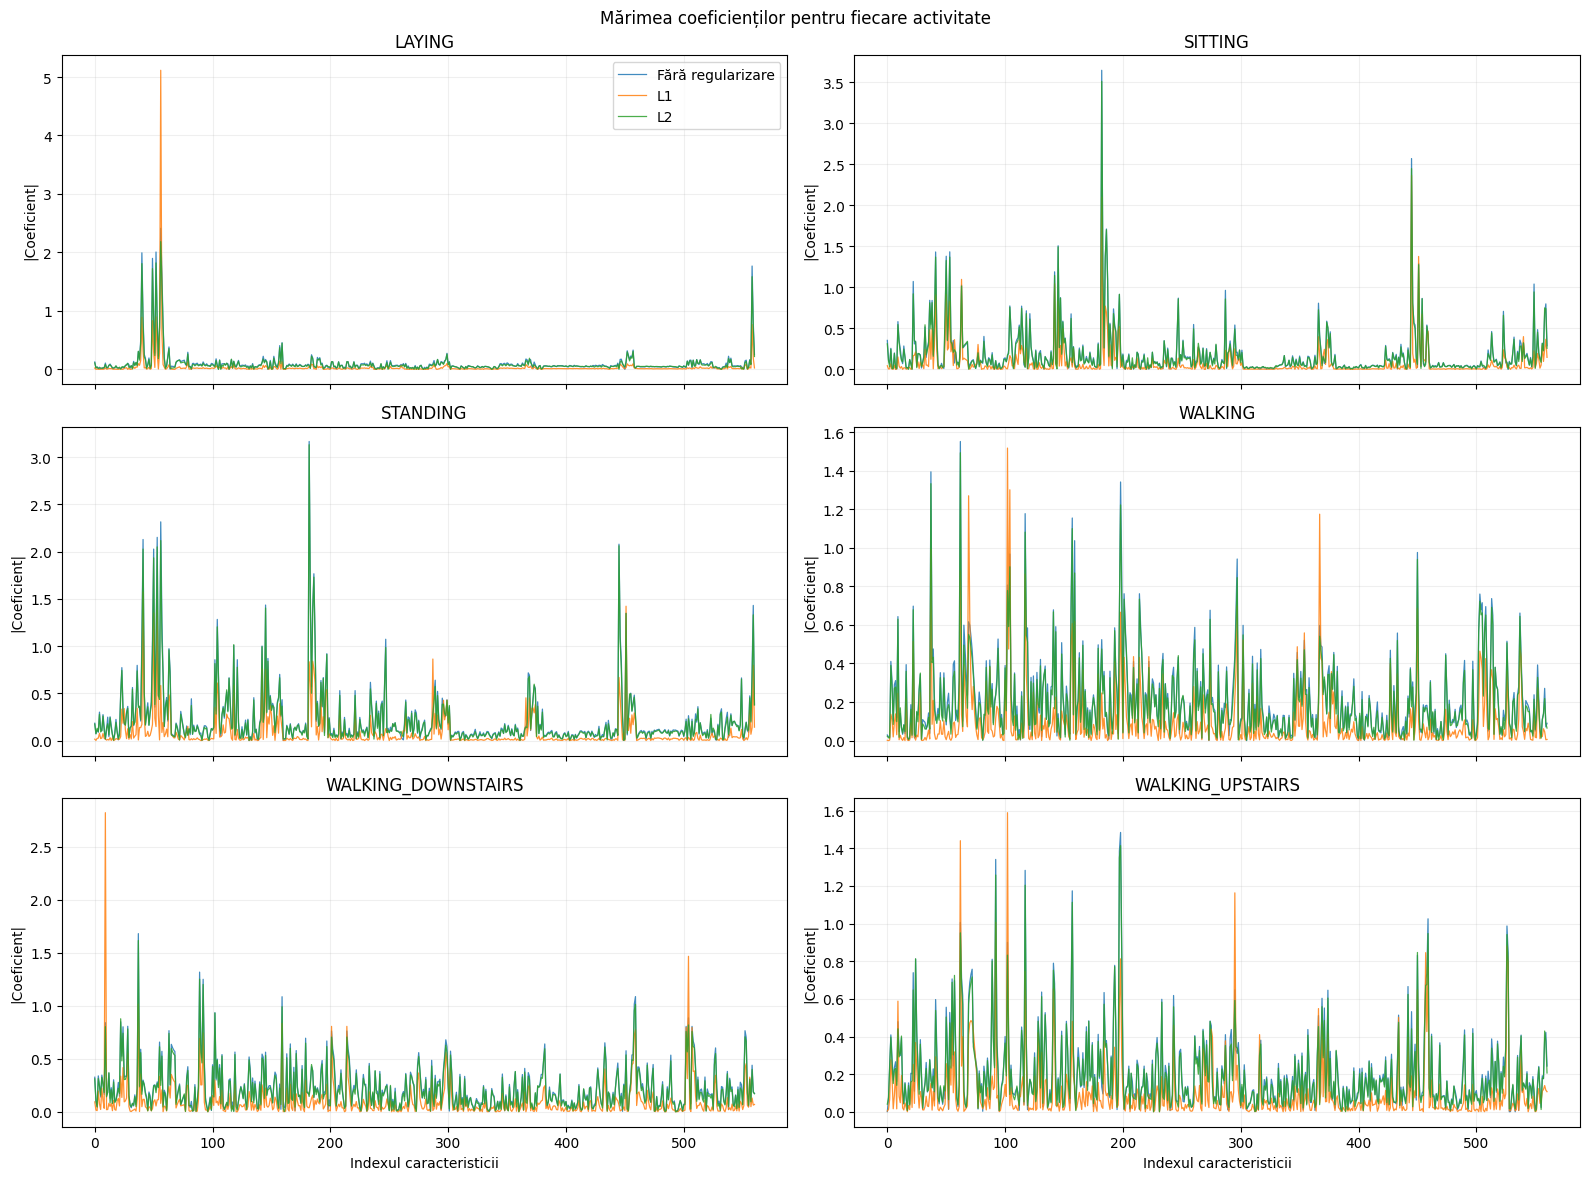

In [6]:
coef_summary = []
for name, model in models.items():
    coef = model.coef_
    coef_summary.append({
        'Model': name, 'Media |coeficient|': np.abs(coef).mean(),
        'Maxim |coeficient|': np.abs(coef).max(),
        'Coeficienți zero': int(np.sum(np.isclose(coef, 0, atol=1e-8)))})
display(pd.DataFrame(coef_summary).set_index('Model'))

fig, axes = plt.subplots(3, 2, figsize=(16, 12), sharex=True)
for class_idx, ax in enumerate(axes.flat):
    for name, model in models.items():
        ax.plot(np.abs(model.coef_[class_idx]), label=name, linewidth=0.9, alpha=0.85)
    ax.set_title(encoder.classes_[class_idx])
    ax.set_ylabel('|Coeficient|')
    ax.grid(alpha=0.2)
    if class_idx >= 4:
        ax.set_xlabel('Indexul caracteristicii')
axes[0, 0].legend()
fig.suptitle('Mărimea coeficienților pentru fiecare activitate')
fig.tight_layout()
plt.show()

**Răspuns:** Media |coeficientului| este 0,192 fără regularizare, 0,082 pentru L1 și 0,180 pentru L2. Cu `C=10` selectat după acuratețe, L1 nu a anulat exact niciun coeficient în această ajustare, dar i-a micșorat în medie.

## Întrebare 6

* Preziceți și stocați clasa pentru fiecare model.
* De asemenea, stocați probabilitatea pentru clasa prezisă pentru fiecare model. 

In [7]:
predictions = {}
predicted_class_probabilities = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    probabilities = model.predict_proba(X_test)
    class_columns = np.searchsorted(model.classes_, y_pred)
    predictions[name] = y_pred
    predicted_class_probabilities[name] = probabilities[np.arange(len(y_pred)), class_columns]
    print(f'{name}: {len(y_pred)} predicții, probabilitatea medie a clasei prezise = '
          f'{predicted_class_probabilities[name].mean():.3f}')

Fără regularizare: 2060 predicții, probabilitatea medie a clasei prezise = 0.975
L1: 2060 predicții, probabilitatea medie a clasei prezise = 0.951
L2: 2060 predicții, probabilitatea medie a clasei prezise = 0.974


Probabilitatea stocată pentru fiecare observație corespunde clasei prezise de acel model.

## Întrebarea 7

Pentru fiecare model, calculați următoarele măsurători de eroare: 

* acuratețe
* precizie
* recall
* fscore
* matricea de confuzie

Decideți cum să combinați metricile multi-clasă într-o singură valoare pentru fiecare model.

Folosim media **macro** pentru precizie, recall și F1: fiecare clasă are aceeași pondere. Acuratețea este proporția globală de predicții corecte.

In [8]:
metric_rows = []
confusion_matrices = {}
for name, y_pred in predictions.items():
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average='macro', zero_division=0)
    metric_rows.append({'Model': name, 'Acuratețe': accuracy_score(y_test, y_pred),
                        'Precizie macro': precision, 'Recall macro': recall,
                        'F1 macro': f1})
    confusion_matrices[name] = confusion_matrix(
        y_test, y_pred, labels=np.arange(len(encoder.classes_)))
metrics = pd.DataFrame(metric_rows).set_index('Model')
display(metrics.round(4))
for name, matrix in confusion_matrices.items():
    print(f'Matricea de confuzie — {name} (rânduri = real, coloane = prezis):')
    display(pd.DataFrame(matrix, index=encoder.classes_, columns=encoder.classes_))

,Acuratețe,Precizie macro,Recall macro,F1 macro
Model,,,,
Fără regularizare,0.9864,0.9871,0.9872,0.9871
L1,0.9733,0.9738,0.9740,0.9739
L2,0.9850,0.9854,0.9857,0.9855


Matricea de confuzie — Fără regularizare (rânduri = real, coloane = prezis):


,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
LAYING,389,0,0,0,0,0
SITTING,0,344,11,0,0,1
STANDING,0,14,367,0,0,0
WALKING,0,0,0,344,0,0
WALKING_DOWNSTAIRS,0,0,0,0,281,0
WALKING_UPSTAIRS,0,0,0,2,0,307


Matricea de confuzie — L1 (rânduri = real, coloane = prezis):


,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
LAYING,389,0,0,0,0,0
SITTING,0,339,16,0,0,1
STANDING,0,25,356,0,0,0
WALKING,0,0,0,340,2,2
WALKING_DOWNSTAIRS,0,0,0,0,275,6
WALKING_UPSTAIRS,0,0,0,2,1,306


Matricea de confuzie — L2 (rânduri = real, coloane = prezis):


,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
LAYING,389,0,0,0,0,0
SITTING,0,344,11,0,0,1
STANDING,0,14,367,0,0,0
WALKING,0,0,0,342,1,1
WALKING_DOWNSTAIRS,0,0,0,0,281,0
WALKING_UPSTAIRS,0,0,0,2,1,306


## Întrebarea 8

Afișați sau reprezentați grafic matricea de confuzie pentru fiecare model.

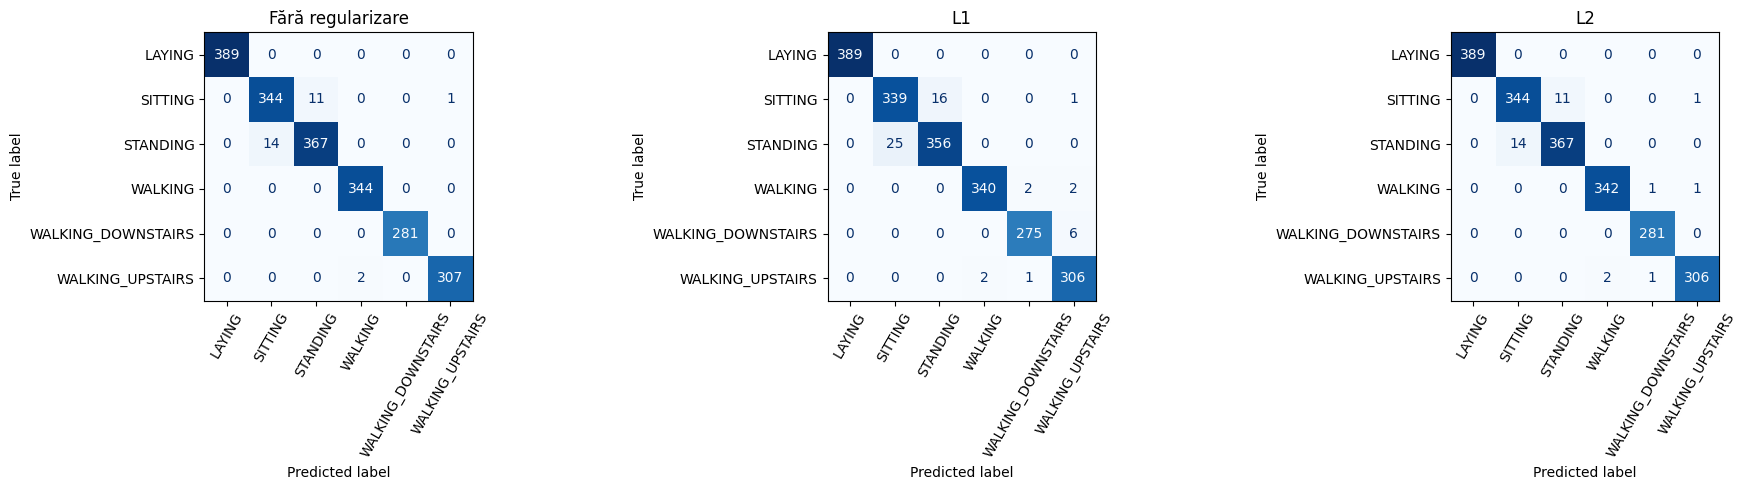

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (name, matrix) in zip(axes, confusion_matrices.items()):
    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=matrix, display_labels=encoder.classes_)
    display_matrix.plot(ax=ax, cmap='Blues', colorbar=False,
                        xticks_rotation=60, values_format='d')
    ax.set_title(name)
fig.tight_layout()
plt.show()

**Concluzie:** Acuratețea este 0,9864 fără regularizare, 0,9850 cu L2 și 0,9733 cu L1. F1 macro este, în aceeași ordine, 0,9871, 0,9855 și 0,9739. Cele mai multe erori sunt între `SITTING` și `STANDING`.